In [1]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

# Shape Generation

In the basics tutorial, we already saw how the shape-generating method ELLIPSIS is able to generate spatial shapes forming an abrupt shift cluster on a geographic map. <br>
Here, we want to demonstrate all kinds of shape-generating methods available.

## SINGLE

The SINGLE shape-generator acts as the default case when adding a background or a shift to the PONDS. It adds the feature to every cell of the grid. Its name comes from the idea that PONDS can also be used to generate a single time series (default lat_size = default lon_size = 1). However, this method is also valid for PONDS grids larger than (1x1). This is especially usefull, when wanting to add a background like a noise to the whole dataset and not just to certain cells.

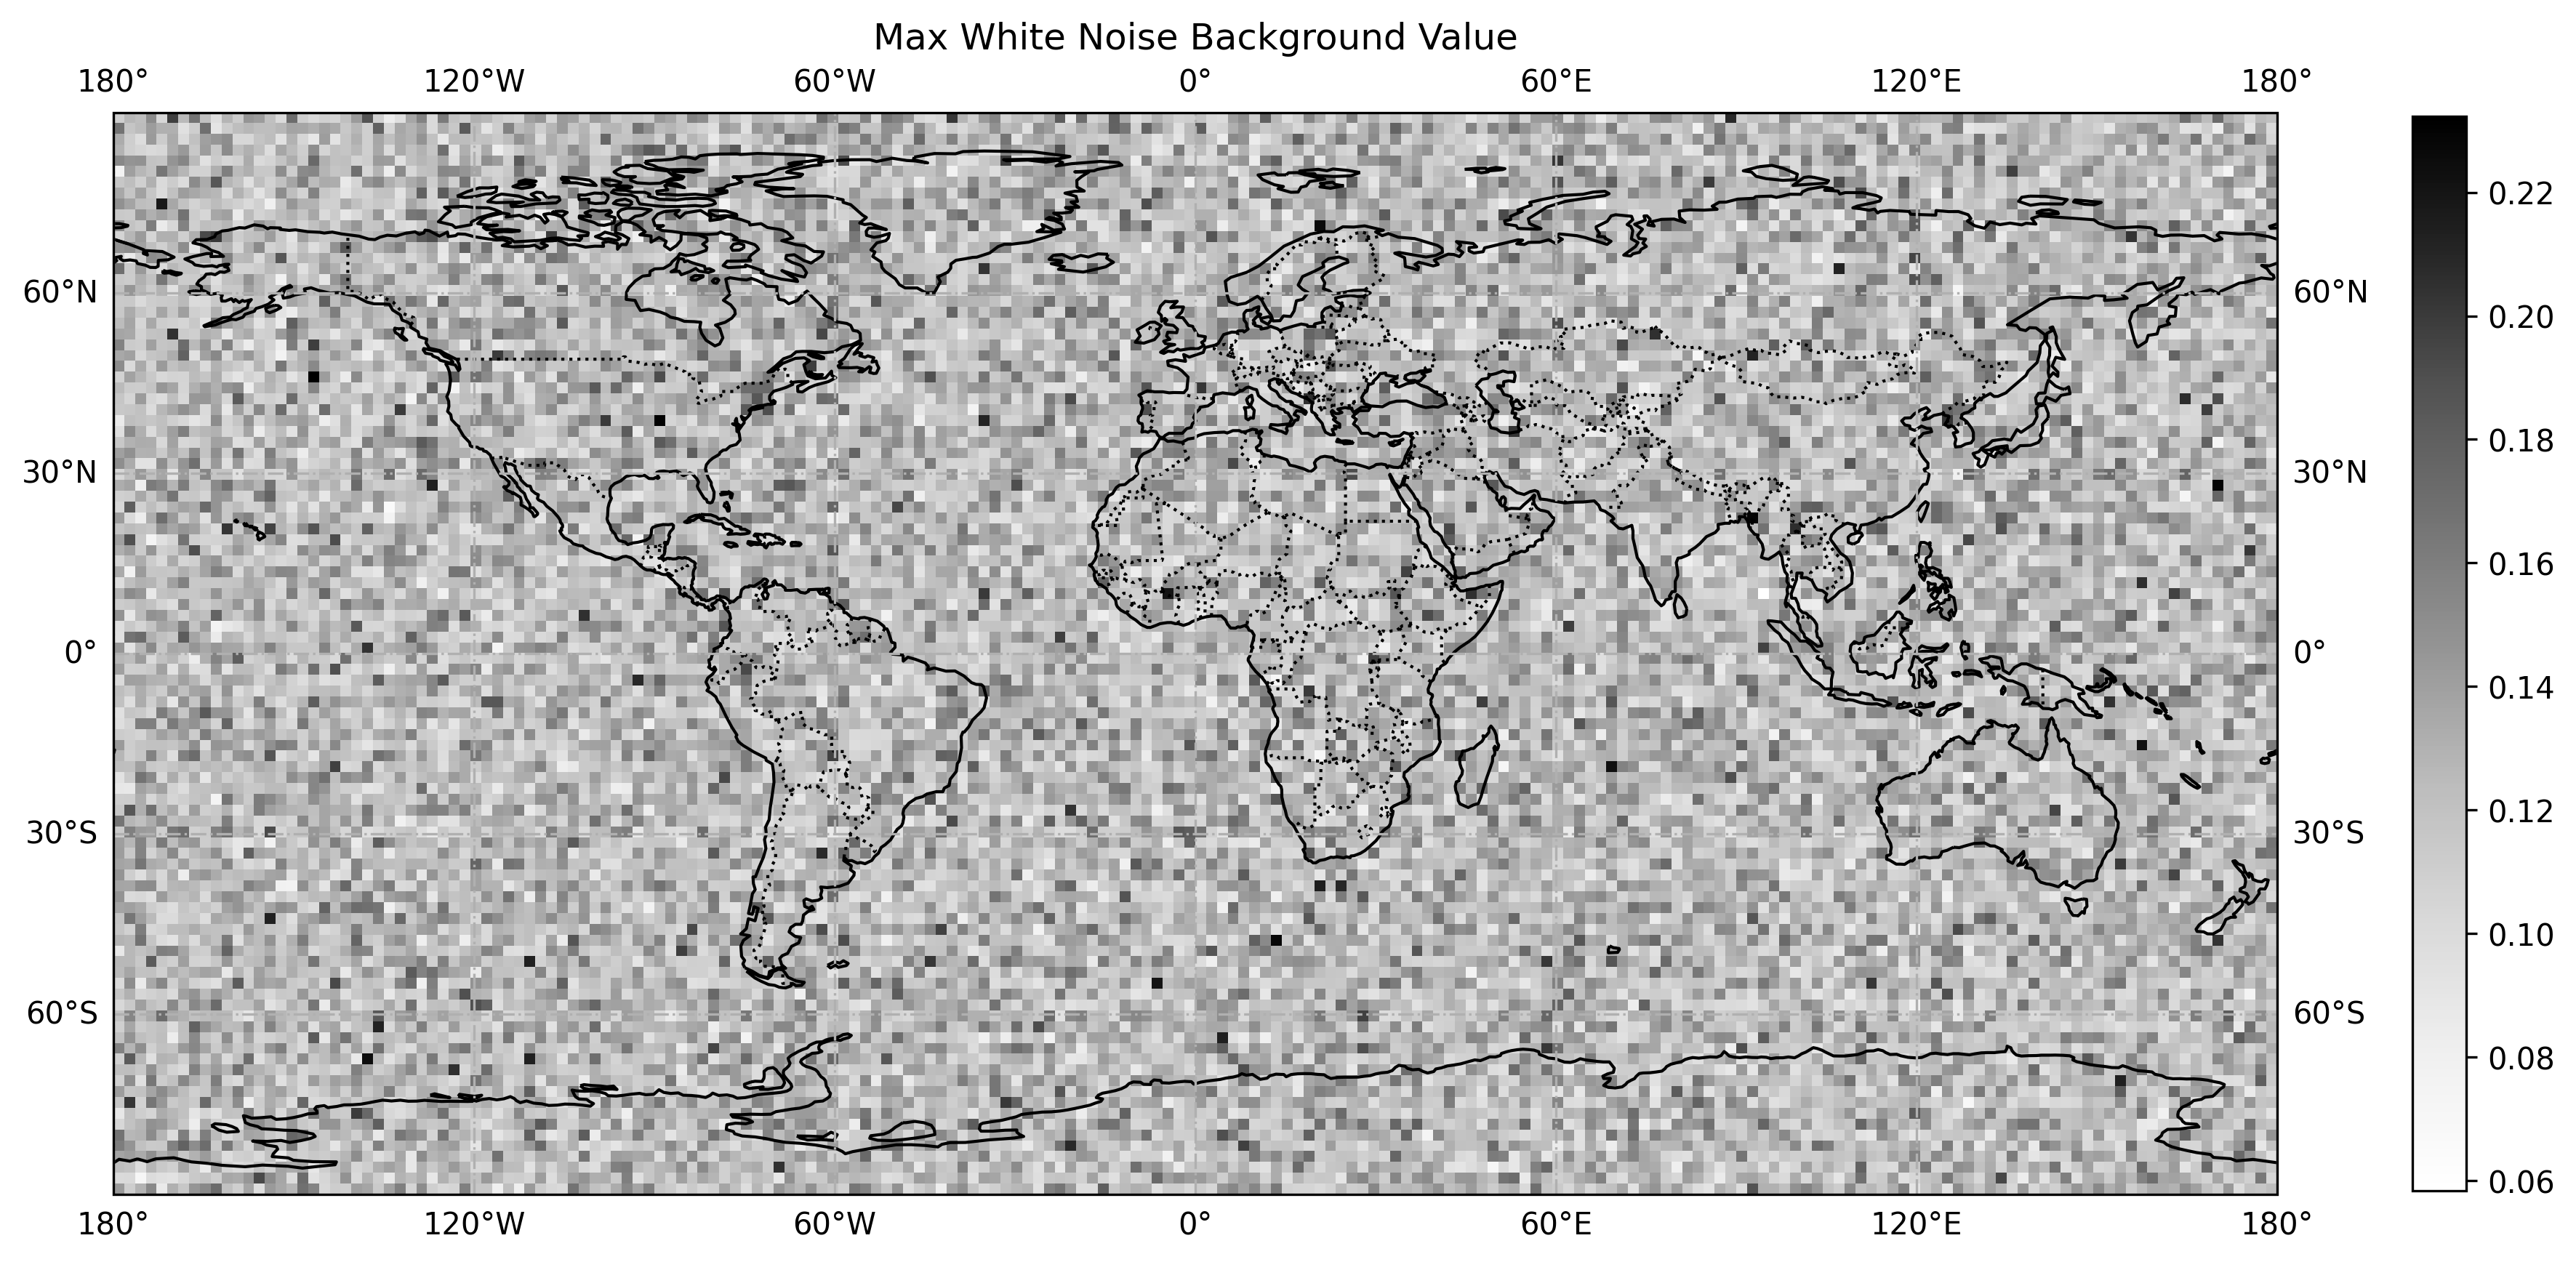

In [2]:
from ponds import PONDS, WhiteNoise, SINGLE

pd = PONDS(
    lat_size=100,
    lon_size=200,
)

pd.add_background(
    background_method=WhiteNoise(),
    shape_method=SINGLE(),
)

fig, ax = pd.worldmap()
ax.set_title("Max White Noise Background Value")
im = ax.imshow(
    np.max(pd.data.ts.values, axis=0),
    cmap="Greys",
    extent=ax.get_extent(),
)
fig.colorbar(im, shrink=0.8)
plt.show()

## ELLIPSIS

Like the name suggests, this shape-generating method draws an ellipsis on the map. The user can specify its location and its extention in latitudinal and longitudinal directions.

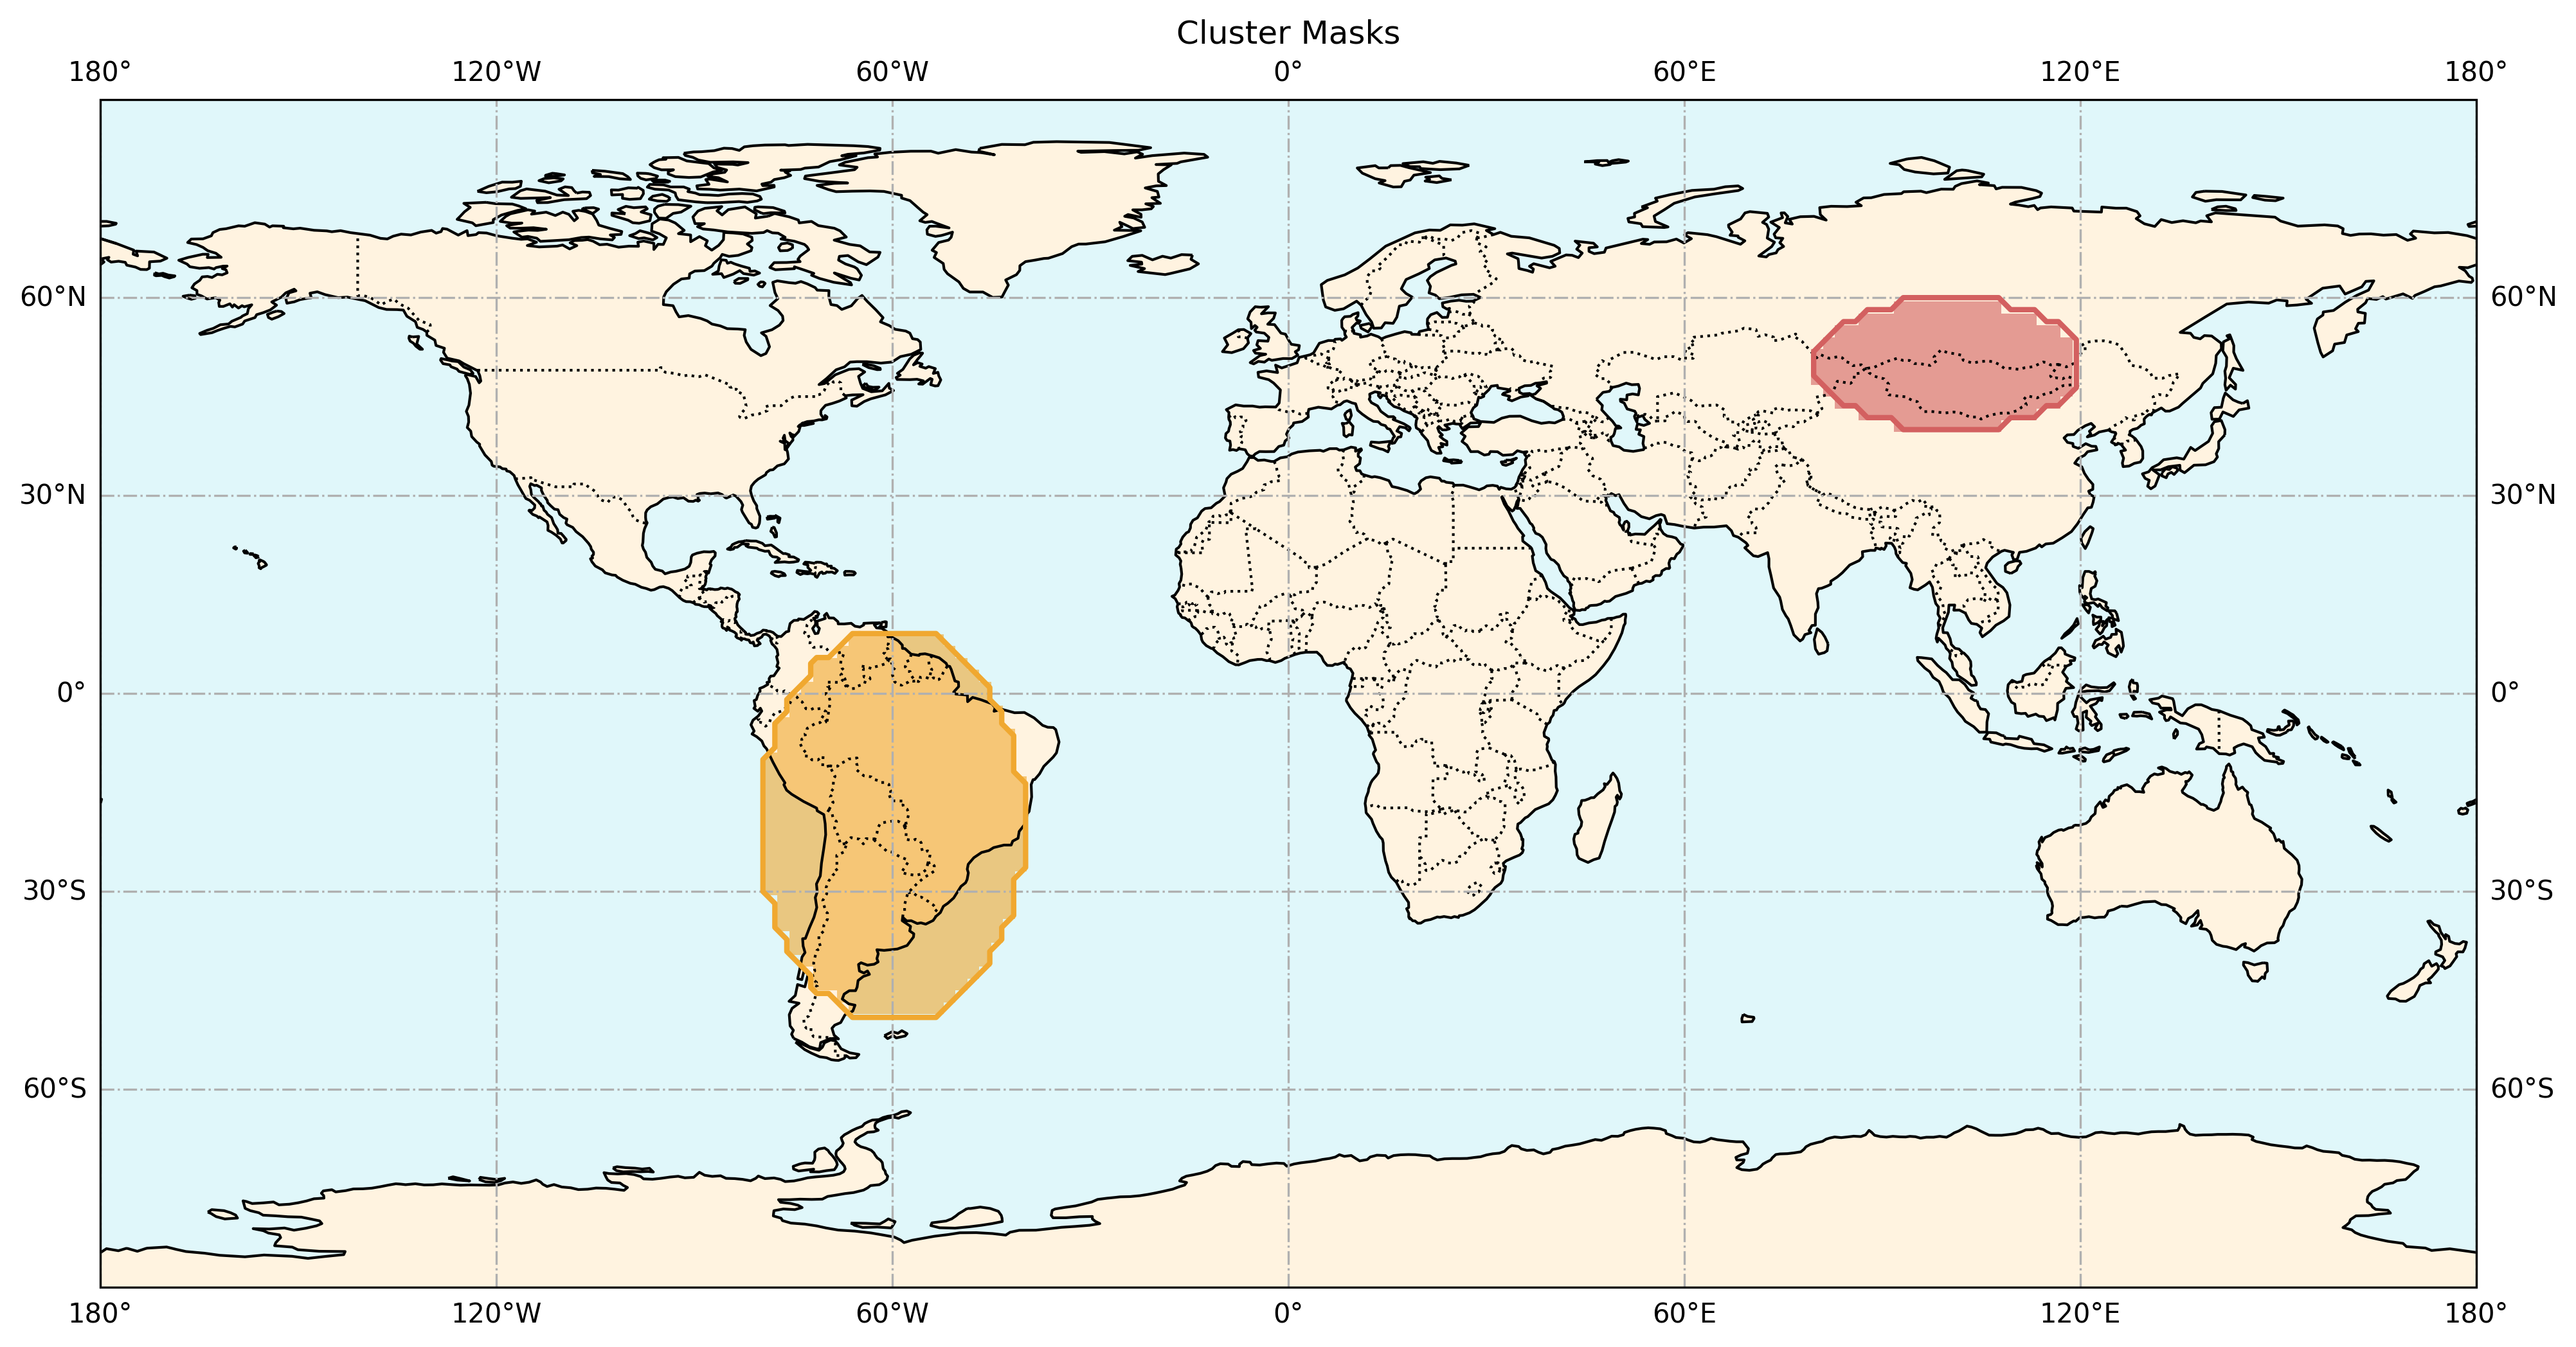

In [5]:
from ponds import PONDS, SIGMOID, ELLIPSIS

pd = PONDS(
    lat_size=100,
    lon_size=200,
)

# add a smaller cluster around central Asia
pd.add_shift(
    shift_method=SIGMOID(shift_seed=1),
    shape_method=ELLIPSIS(
        center_lat=50,  # central location of ellipsis in latitudes
        center_lon=100,  # central location of ellipsis in longitudes
        ecc_lat=10,  # eccentricity of ellipsis in latitudes
        ecc_lon=20,  # eccentricity of ellipsis in longitudes
    ),
)

# add a larger cluster around South America
pd.add_shift(
    shift_method=SIGMOID(shift_seed=2),
    shape_method=ELLIPSIS(
        center_lat=-20,  # central location of ellipsis in latitudes
        center_lon=-60,  # central location of ellipsis in longitudes
        ecc_lat=30,  # eccentricity of ellipsis in latitudes
        ecc_lon=20,  # eccentricity of ellipsis in longitudes
    ),
)

fig, ax = pd.worldmap()
plt.show()

## BLOB

This shape-generator is trying to mimic more naturally found shift clusters (eg. [Angevaare and Drijfhout, 2025] Fig.7+8). Its underlying implementation creates some balls around a given location and connects them together simillar to water droplets connecting to each other via surface tension.<br>
Hence, its central 'physics' parameter is goo (like sticky goo) which determines the 'tension pull'. If this parameter is not specified by the user, the optimal value is found automatically so the balls are just connected to a single blob.

Currently, the `size` parameter does not really correspond to the actual size of the cluster mask in lats and lons. It can be seen more as a relative measure.

`max_belly` is the parameter defining how many balls to be connected are placed around the location. Due to randomness, sometimes these balls align and therefore can get swallowed by other balls. This parameter not always gives certainty about the complexity (i.o.w. the actual number of 'bellys') of the shape.

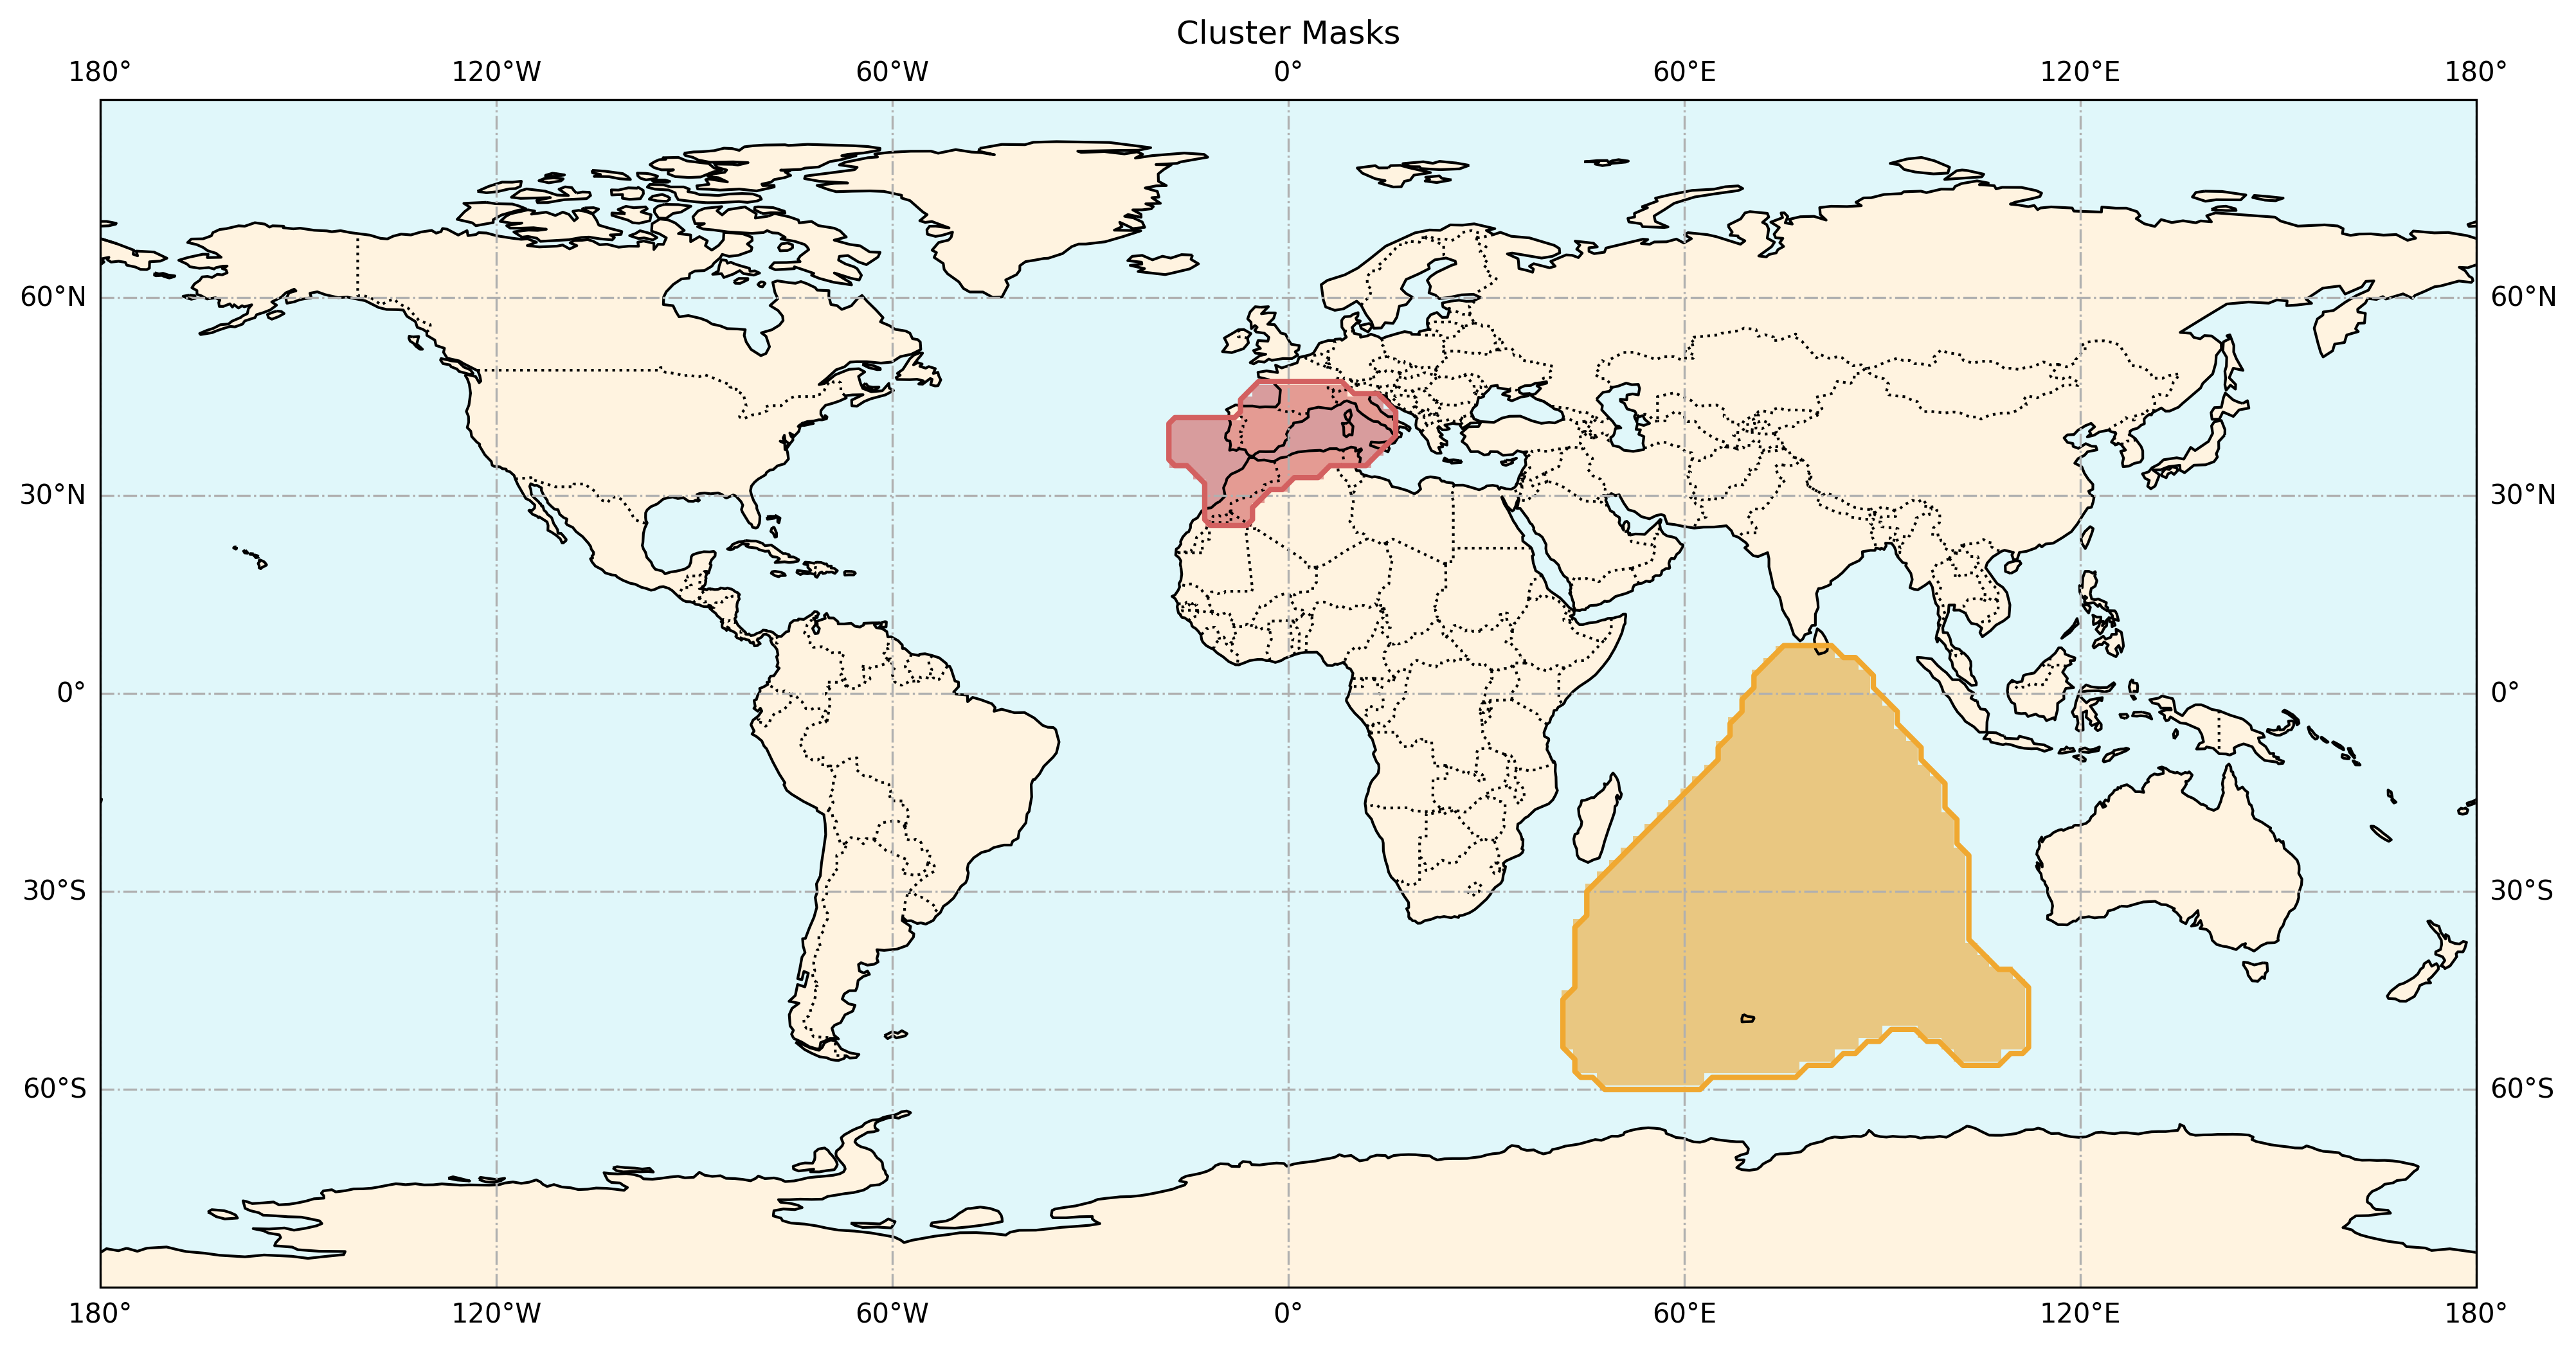

In [6]:
from ponds import PONDS, SIGMOID, BLOB

pd = PONDS(
    lat_size=100,
    lon_size=200,
)

# add a smaller cluster over South Europe/North Africa
pd.add_shift(
    shift_method=SIGMOID(shift_seed=1),
    shape_method=BLOB(
        center_lat=40,
        center_lon=0,
        size=3,
        max_bellys=5,
        shape_seed=3,
    ),
)

# add a larger cluster over the Indian Ocean
pd.add_shift(
    shift_method=SIGMOID(shift_seed=2),
    shape_method=BLOB(
        center_lat=-30,
        center_lon=80,
        size=7,
        max_bellys=10,
        shape_seed=5,
    ),
)

fig, ax = pd.worldmap()

## CUSTOM

This shape-generating method is not actually generating a shape. When using this method, a custom made, boolean mask can be fed into the pipeline. This can be usefull when the user knows the shape of the shift cluster exactly (e.g. as seen in nature) and wants to mimic its outlines.

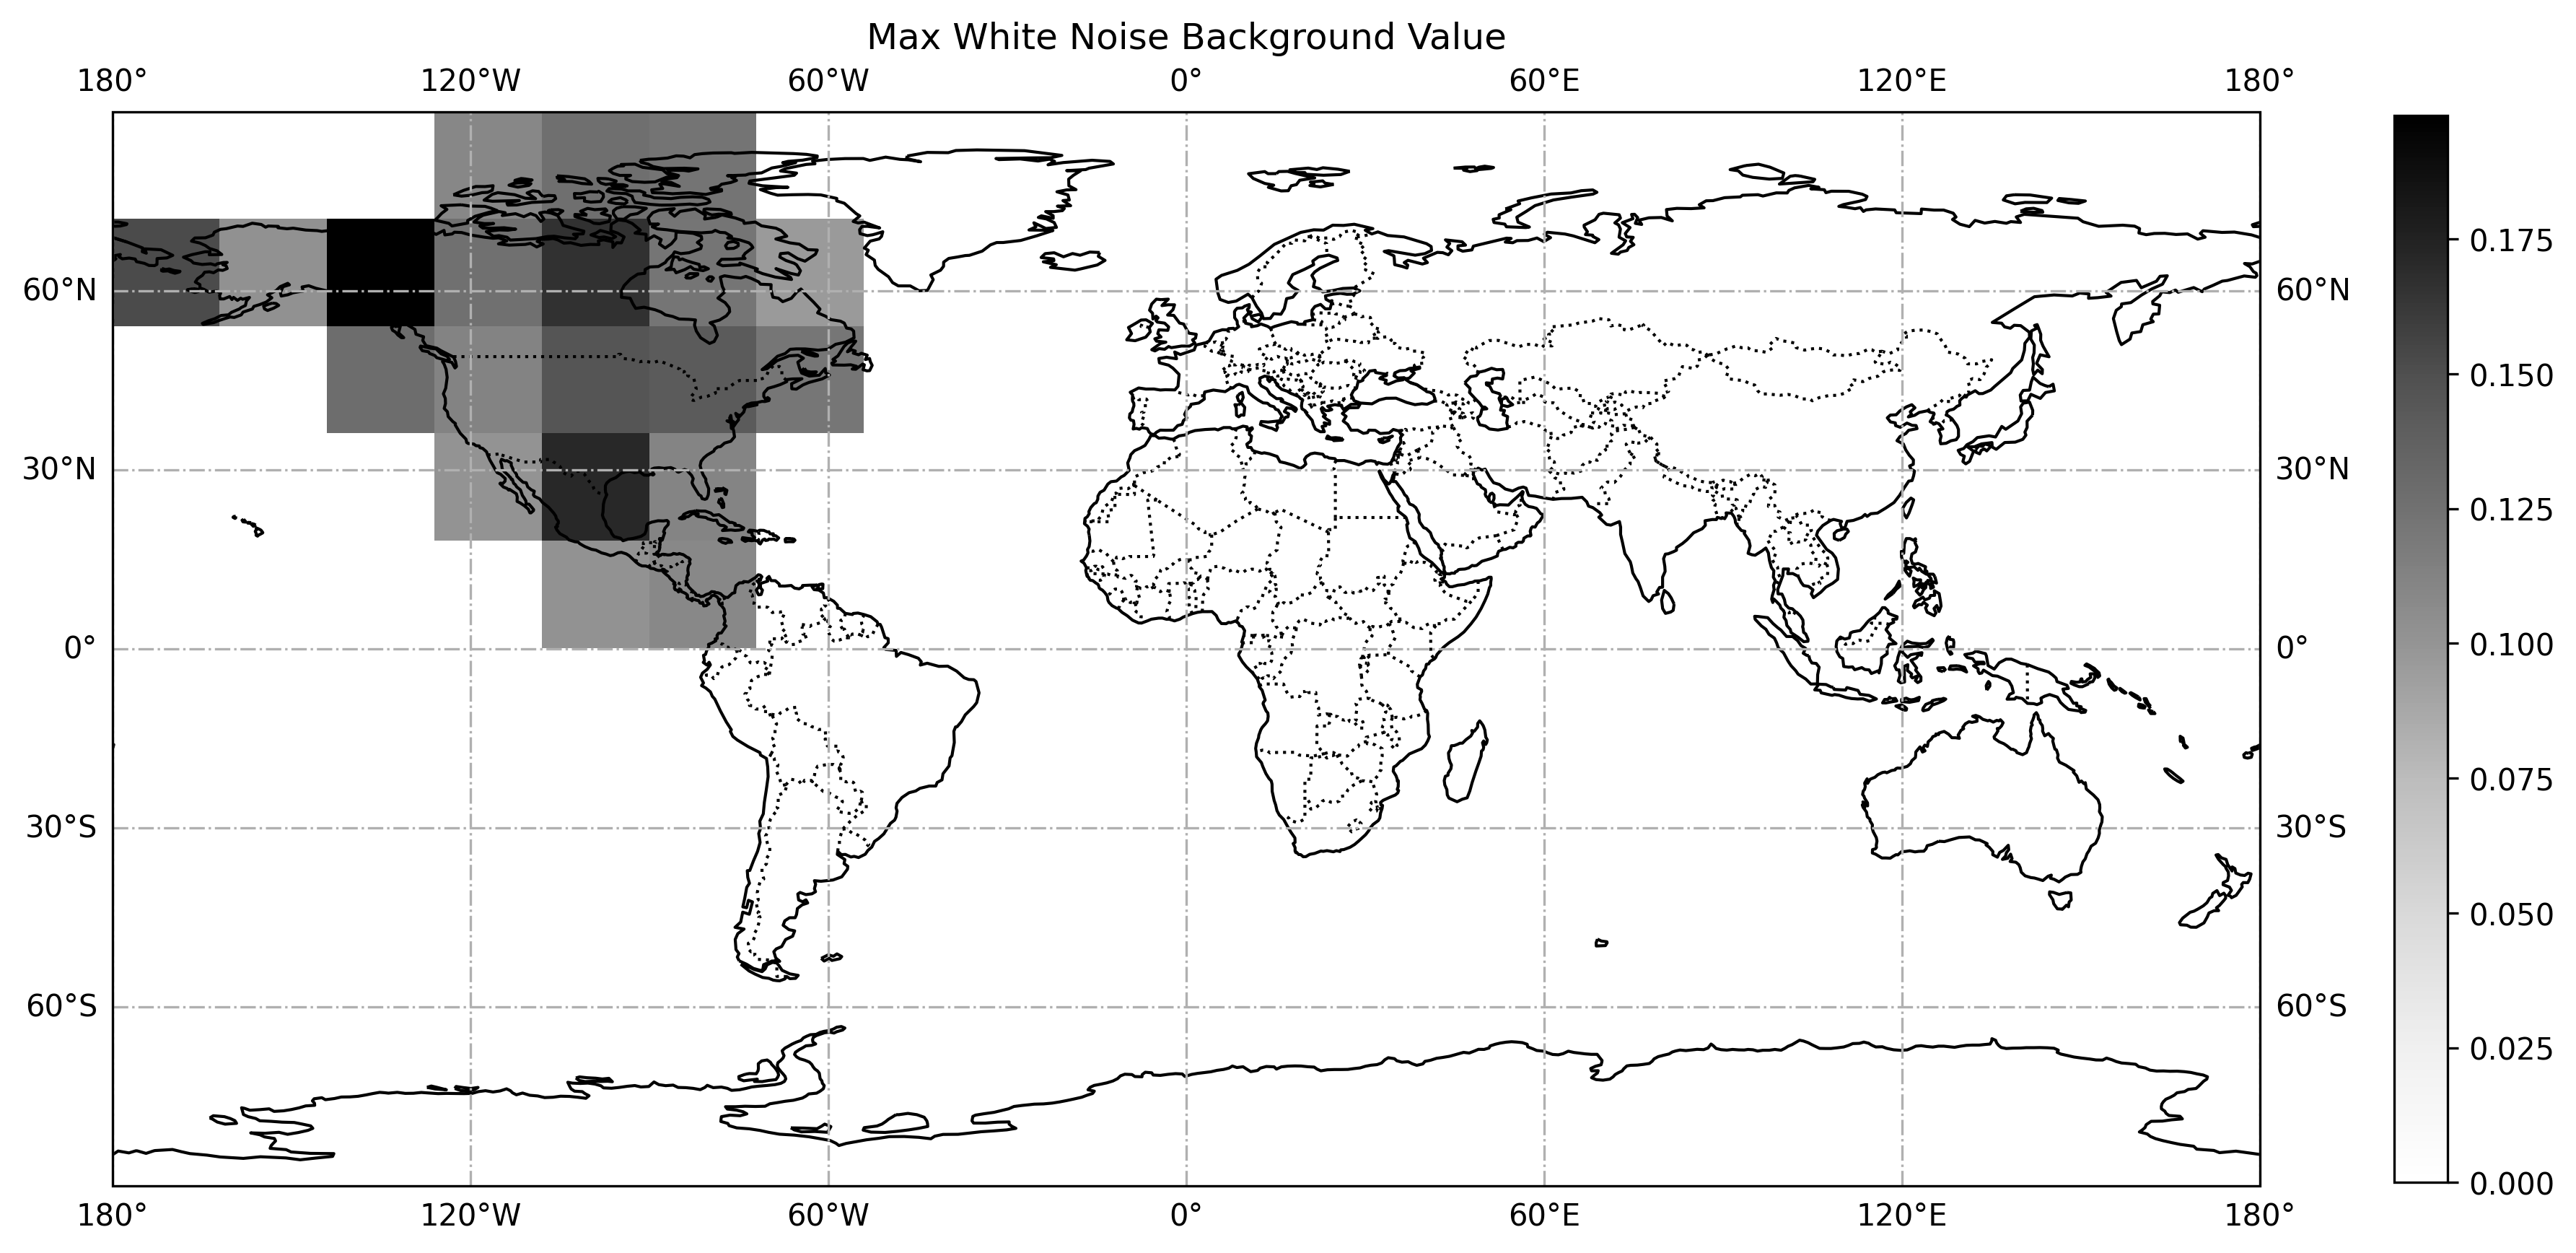

In [7]:
from ponds import PONDS, WhiteNoise, CUSTOM

pd = PONDS(
    lat_size=10,
    lon_size=20,
)

# custom cluster covering all of North America
custom_mask = np.array(
    [
        [0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    ],
    dtype=bool,
)

pd.add_background(
    background_method=WhiteNoise(),
    shape_method=CUSTOM(
        shape_mask=custom_mask,
    ),
)

fig, ax = pd.worldmap()
ax.set_title("Max White Noise Background Value")
im = ax.imshow(
    np.max(pd.data.ts.values, axis=0),
    cmap="Greys",
    extent=ax.get_extent(),
)
fig.colorbar(im, shrink=0.8)
plt.show()